# House 1 washing-machine disaggregation

This notebook uses the official cleaned House 1 CSV to predict the washing-machine channel (Appliance 5) from the matching whole-house aggregate at one-minute resolution. It compares an always-off predictor with a modest Random Forest. Features are aggregate power at the current minute and 1, 2, 5, and 15 minutes earlier; no target lags or future readings are used.

The split is chronological: the first 80% of valid feature/target timestamps are training data and the final 20% are test data. To keep fitting practical on a normal laptop, the training block is evenly thinned to at most 150,000 rows, while the test set remains complete. `Issues == 1` readings and missing feature/target rows are excluded. Both methods are evaluated on exactly the same test timestamps. The energy error is the absolute difference between predicted and actual test-period washer energy, in kWh, divided by actual test-period washer energy.

## Research context and project choices

The REFIT dataset description (Murray et al., 2017) establishes the dataset's roughly 8-second readings and household/appliance context. Khazaei et al. (2020) compare low-complexity Decision Tree, KNN, and DBSCAN NILM methods plus preprocessing on REFIT and REDD resampled to one minute; this supports a manageable model and common minute interval, not a claim that Random Forest won that comparison. NILMTK (Batra et al., 2014) motivates explicit preprocessing, baselines, and metrics. Liao et al. (2014) provides context for coarser meter intervals. Breiman (2001) is the general Random Forest reference. Full citations and DOI links are in the project-root `REFERENCES.md`.

The Random Forest here is our own compact supervised-regression baseline, not a reproduction of a cited model or published result. Current/past aggregate features and the chronological split are chosen to avoid future-information leakage. The reported metrics are computed from this local House 1 test period; they should not be compared numerically with papers that use different houses, sampling intervals, preprocessing, or splits.

In [1]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "cleaned").is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project data/cleaned folder from the current directory.")

PROJECT_ROOT = find_project_root()
CLEAN_FILE = PROJECT_ROOT / "data" / "cleaned" / "CLEAN_REFIT_081116" / "CLEAN_House1.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "03_disaggregation_model"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COLUMN = "Appliance5"
FEATURE_LAGS_MINUTES = [0, 1, 2, 5, 15]
MAX_TRAINING_ROWS = 150_000
if not CLEAN_FILE.is_file():
    raise FileNotFoundError(f"Expected official cleaned House 1 file was not found: {CLEAN_FILE}")

frame = pd.read_csv(
    CLEAN_FILE,
    usecols=["Time", "Aggregate", TARGET_COLUMN, "Issues"],
    dtype={"Aggregate": "float32", TARGET_COLUMN: "float32", "Issues": "float32"},
)
input_rows = len(frame)
frame["Time"] = pd.to_datetime(frame["Time"], errors="coerce")
invalid_timestamps = int(frame["Time"].isna().sum())
frame = frame.dropna(subset=["Time"])
duplicate_timestamps = int(frame["Time"].duplicated(keep="last").sum())
frame = frame.drop_duplicates("Time", keep="last").sort_values("Time", kind="stable").set_index("Time")
issue_rows = int(frame["Issues"].eq(1).sum())

# Exclude flagged sensor-disagreement records before one-minute averaging.
power = frame[["Aggregate", TARGET_COLUMN]].copy()
power.loc[frame["Issues"].eq(1), ["Aggregate", TARGET_COLUMN]] = np.nan
minute = power.resample("1min").mean()
full_index = pd.date_range(minute.index.min().floor("min"), minute.index.max().floor("min"), freq="1min")
minute = minute.reindex(full_index)
minute.index.name = "Time"

features = pd.DataFrame(index=minute.index)
for lag in FEATURE_LAGS_MINUTES:
    feature_name = "aggregate_current_w" if lag == 0 else f"aggregate_lag_{lag}m_w"
    features[feature_name] = minute["Aggregate"].shift(lag)
dataset = features.assign(target_w=minute[TARGET_COLUMN]).dropna()
if len(dataset) < 1000:
    raise ValueError(f"Not enough complete one-minute feature/target rows for modeling: {len(dataset)}")

split_position = int(len(dataset) * 0.8)
training_block = dataset.iloc[:split_position]
test = dataset.iloc[split_position:]
sampling_step = max(1, math.ceil(len(training_block) / MAX_TRAINING_ROWS))
train = training_block.iloc[::sampling_step]
feature_columns = list(features.columns)

print(f"Input rows: {input_rows:,}; invalid timestamps: {invalid_timestamps:,}; duplicate timestamps removed: {duplicate_timestamps:,}")
print(f"Issues-flagged rows excluded: {issue_rows:,}")
print(f"Valid one-minute feature/target rows: {len(dataset):,}")
print(f"Train: {len(train):,} sampled rows ({train.index.min()} to {train.index.max()})")
print(f"Test: {len(test):,} rows ({test.index.min()} to {test.index.max()})")
print(f"Features: {feature_columns}")

Input rows: 6,960,008; invalid timestamps: 0; duplicate timestamps removed: 0
Issues-flagged rows excluded: 58,183
Valid one-minute feature/target rows: 788,926
Train: 126,228 sampled rows (2013-10-09 13:21:00 to 2015-02-21 20:22:00)
Test: 157,786 rows (2015-02-21 20:27:00 to 2015-07-10 11:56:00)
Features: ['aggregate_current_w', 'aggregate_lag_1m_w', 'aggregate_lag_2m_w', 'aggregate_lag_5m_w', 'aggregate_lag_15m_w']


In [2]:
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)
model.fit(train[feature_columns], train["target_w"])

actual = test["target_w"]
always_off = np.zeros(len(test), dtype=float)
random_forest = np.clip(model.predict(test[feature_columns]), 0, None)
predictions = pd.DataFrame({
    "actual_w": actual,
    "always_off_w": always_off,
    "random_forest_w": random_forest,
    "aggregate_current_w": test["aggregate_current_w"],
}, index=test.index)
if not predictions.index.equals(test.index):
    raise AssertionError("Baseline and Random Forest predictions must use identical test timestamps.")

actual_energy_kwh = float(actual.sum() / 60_000)
metric_rows = []
for method, prediction in [("Always-off baseline", always_off), ("Random Forest", random_forest)]:
    predicted_energy_kwh = float(np.sum(prediction) / 60_000)
    absolute_energy_error_kwh = abs(predicted_energy_kwh - actual_energy_kwh)
    metric_rows.append({
        "model": method,
        "test_timestamps": len(actual),
        "mae_w": mean_absolute_error(actual, prediction),
        "rmse_w": mean_squared_error(actual, prediction) ** 0.5,
        "actual_energy_kwh": actual_energy_kwh,
        "predicted_energy_kwh": predicted_energy_kwh,
        "absolute_energy_error_kwh": absolute_energy_error_kwh,
        "absolute_energy_error_percent": 100 * absolute_energy_error_kwh / actual_energy_kwh if actual_energy_kwh else np.nan,
    })
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(OUTPUT_DIR / "model_metrics.csv", index=False)
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv.gz", compression="gzip", float_format="%.2f")
feature_importance = pd.DataFrame({"feature": feature_columns, "importance": model.feature_importances_})
feature_importance = feature_importance.sort_values("importance", ascending=False)
feature_importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)

print(metrics.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print("\nFeature importance:")
print(feature_importance.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

              model  test_timestamps  mae_w  rmse_w  actual_energy_kwh  predicted_energy_kwh  absolute_energy_error_kwh  absolute_energy_error_percent
Always-off baseline           157786 10.479 135.070             27.558                 0.000                     27.558                        100.000
      Random Forest           157786 12.046 102.365             27.558                24.517                      3.040                         11.033

Feature importance:
            feature  importance
aggregate_current_w       0.363
 aggregate_lag_5m_w       0.196
 aggregate_lag_1m_w       0.176
aggregate_lag_15m_w       0.170
 aggregate_lag_2m_w       0.095


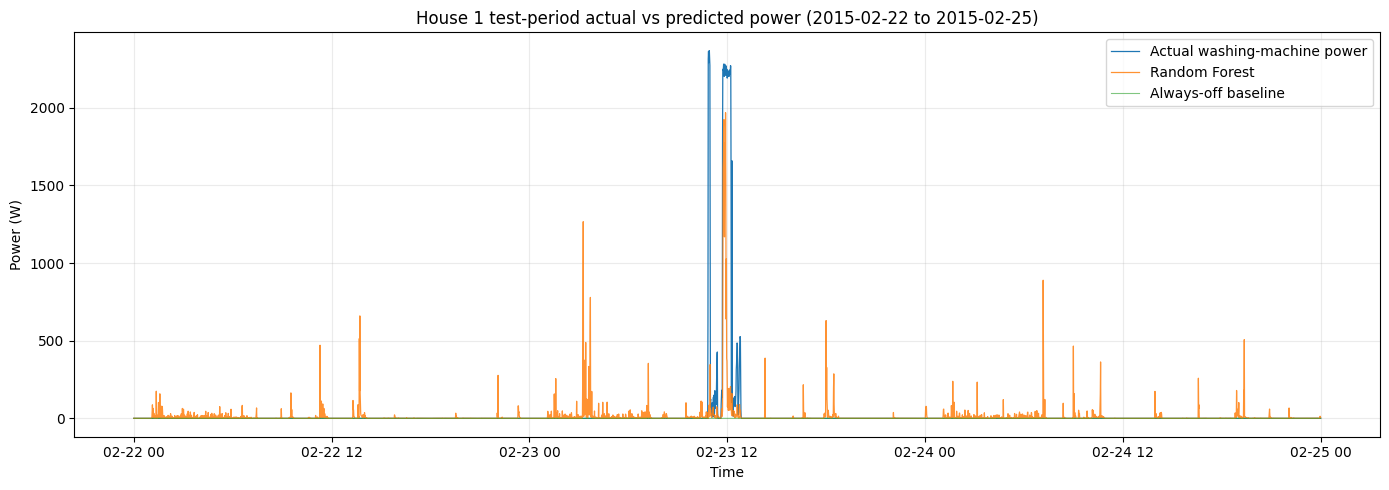

Saved metrics, predictions, plot, and report to outputs\03_disaggregation_model
Failure cases saved: ['False positive while washer target is off', 'Underprediction during a high washer reading']


In [3]:
daily_test_energy = predictions["actual_w"].resample("D").sum()
peak_day = daily_test_energy.idxmax().normalize()
plot_start = max(peak_day - pd.Timedelta(days=1), predictions.index.min().normalize())
plot_end = min(plot_start + pd.Timedelta(days=3), predictions.index.max())
plot_data = predictions.loc[plot_start:plot_end]
fig, axis = plt.subplots(figsize=(14, 5))
axis.plot(plot_data.index, plot_data["actual_w"], label="Actual washing-machine power", linewidth=0.9)
axis.plot(plot_data.index, plot_data["random_forest_w"], label="Random Forest", linewidth=0.9, alpha=0.85)
axis.plot(plot_data.index, plot_data["always_off_w"], label="Always-off baseline", linewidth=0.8, alpha=0.6)
axis.set(title=f"House 1 test-period actual vs predicted power ({plot_start.date()} to {plot_end.date()})",
         xlabel="Time", ylabel="Power (W)")
axis.grid(alpha=0.25)
axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

error_data = predictions.copy()
error_data["absolute_error_w"] = (error_data["actual_w"] - error_data["random_forest_w"]).abs()
zero_actual = error_data.loc[error_data["actual_w"].eq(0)]
false_positive = zero_actual.loc[zero_actual["random_forest_w"].idxmax()] if not zero_actual.empty else error_data.loc[error_data["absolute_error_w"].idxmax()]
active_actual = error_data.loc[error_data["actual_w"].ge(200)].copy()
active_actual["underprediction_w"] = active_actual["actual_w"] - active_actual["random_forest_w"]
underprediction = active_actual.loc[active_actual["underprediction_w"].idxmax()] if not active_actual.empty else error_data.loc[error_data["absolute_error_w"].idxmax()]

failure_rows = []
for label, row in [("False positive while washer target is off", false_positive),
                   ("Underprediction during a high washer reading", underprediction)]:
    timestamp = row.name
    failure_rows.append({
        "case": label,
        "timestamp": timestamp,
        "aggregate_current_w": float(row["aggregate_current_w"]),
        "actual_w": float(row["actual_w"]),
        "random_forest_w": float(row["random_forest_w"]),
        "absolute_error_w": float(row["absolute_error_w"]),
    })
failures = pd.DataFrame(failure_rows)
failures.to_csv(OUTPUT_DIR / "failure_examples.csv", index=False, date_format="%Y-%m-%d %H:%M:%S")

predictions_by_day = predictions.resample("D").agg({"actual_w": "sum", "random_forest_w": "sum"})
failure_examples_text = [
    f"1. At {false_positive.name}, the washer target is {false_positive['actual_w']:.1f} W while the model predicts {false_positive['random_forest_w']:.1f} W (aggregate {false_positive['aggregate_current_w']:.1f} W). Other household loads can produce an aggregate pattern that resembles washer activity.",
    f"2. At {underprediction.name}, actual washer power is {underprediction['actual_w']:.1f} W while the model predicts {underprediction['random_forest_w']:.1f} W (aggregate {underprediction['aggregate_current_w']:.1f} W). Similar aggregate totals can come from different appliance combinations, and the model's tree averages smooth sharp washer transitions.",
]

rf_metrics = metrics.loc[metrics["model"] == "Random Forest"].iloc[0]
baseline_metrics = metrics.loc[metrics["model"] == "Always-off baseline"].iloc[0]
report = [
    "# House 1 washing-machine disaggregation results",
    "",
    "## Data and validation design",
    "",
    f"Official cleaned input: `data/cleaned/CLEAN_REFIT_081116/CLEAN_House1.csv`; target: Appliance 5 washing machine, in watts. The one-minute test uses {len(test):,} valid timestamps from {test.index.min()} through {test.index.max()}. {issue_rows:,} rows with `Issues == 1` were excluded before resampling.",
    f"Features are current aggregate power and aggregate lags at {', '.join(str(x) for x in FEATURE_LAGS_MINUTES[1:])} minutes. The first 80% of complete chronological feature/target timestamps form the training period; the last 20% form the test period. Training was evenly thinned to {len(train):,} rows (at most {MAX_TRAINING_ROWS:,}) for laptop-scale fitting. No future aggregate values or washing-machine target lags are used.",
    "",
    "## Test metrics",
    "",
    metrics.to_string(index=False, float_format=lambda value: f"{value:.3f}"),
    "",
    "Energy error is defined as `abs(predicted test kWh - actual test kWh) / actual test kWh * 100`; energy for one-minute samples is `sum(power_W) / 60,000`. Metrics are computed on the same test timestamps for both methods. The always-off predictor is a meaningful baseline because the washer is at zero for much of the time.",
    "",
    "## Literature context and implementation scope",
    "",
    "Khazaei et al. (2020) provide a directly REFIT-based precedent for comparing simple NILM methods and preprocessing at one-minute resolution; their tested Decision Tree, KNN, and DBSCAN methods are not the Random Forest used here. NILMTK (Batra et al., 2014) motivates explicit baselines and multiple accuracy metrics; Breiman (2001) is the general Random Forest reference. Current/past aggregate lags and the chronological split are this project's leakage-conscious choices. This compact model is not a reproduction of a published NILM method or score. Full citations: project-root `REFERENCES.md`.",
    "",
    "## Observed failure cases",
    "",
    *failure_examples_text,
    "",
    "These examples are selected from the actual test residuals and are saved with their readings in `failure_examples.csv`. Appliance-level ambiguity is unavoidable from one aggregate meter; coincident loads and changing cycle phases can make different washer states look similar at the whole-house level.",
    "",
    "## Plot and outputs",
    "",
    f"`actual_vs_predicted.png` shows a three-day test window around the day with the highest actual washer energy. The Random Forest MAE is {rf_metrics['mae_w']:.1f} W versus {baseline_metrics['mae_w']:.1f} W for always-off; its test-period absolute energy error is {rf_metrics['absolute_energy_error_percent']:.1f}%.",
    "`model_metrics.csv` contains MAE, RMSE, and the defined energy metric. `test_predictions.csv.gz` contains actual, baseline, Random Forest, and aggregate readings at all test timestamps. `feature_importance.csv` contains fitted feature importances; `failure_examples.csv` records the two example errors.",
]
(OUTPUT_DIR / "model_findings.md").write_text("\n".join(report) + "\n", encoding="utf-8")
print(f"Saved metrics, predictions, plot, and report to {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")
print(f"Failure cases saved: {failures['case'].tolist()}")